# Quantum Metal iSWAP example 1 — two concentric transmons coupled directly, lumped readout resonators (Quantcore PDK rebuild)

**What the chip is.** Example 1 of the Qiskit Metal notebook
`docs/circuit-examples/F.Small-quantum-chips/Full-Physical-Design-of-iSWAP-Gates.ipynb` (after Phys. Rev. Applied 10,
034050 (2018), "only roughly": the notebook says the point is the structure of each device, not its exact geometry;
© IBM / Qiskit Metal contributors, Apache-2.0, <https://github.com/qiskit-community/qiskit-metal>; spec
`docs/designs/metal/iswap1_concentric_direct.md`): two `TransmonConcentricType2` qubits (disk + ring with a SQUID, mm
scale: ring radius 2 mm) at −45° / 135°, joined by a straight 4.6 mm line between their `pin2` fingers. Each qubit's
`pin3` finger is wired to a corner of a `ResonatorLumped` (a 14-turn meander in a 5 × 5 mm metal frame), whose side
pin goes to a launchpad. A third launchpad carries a drive line that ends open (`OpenToGround`) 500 µm below qubit
1's ring. We distribute the rebuild under GPL-3.0.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
Metal components are drawn through the `metal:<Class>` wrapper with the tutorial's options; the chip, the stack, the
junctions, the netlist and the LOM are ours.

| | Qiskit Metal example 1 | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` 32 × 20 mm centred at (1, 3) mm | 32 × 25 mm (the 10 mm pockets overhang the source's chip; Designer = Metal + (15, 7.5) mm), with the QCT die frame |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | three `LaunchpadWirebond`s 0.8–1.3 mm inside the chip | the same pads, moved to **100 µm** (`frame.pad_edge`) from the edge they face (south, south, east); the geometry that ends on them follows their ties |
| junctions | SQUIDs (Metal junction lines, 10 nH assumed) | Quantcore trilayer SQUIDs **sized for 4.0 GHz** (the bottom of the PDK band; R_n far below the window, flagged) |
| pockets | never drawn (metal-only cells) | `metal:Rectangle` pockets (lead decision, option b) |
| cheese | none (the notebook never exports GDS) | the PDK band (chip `cheese: "auto"`) |
| lines | `RouteStraight` (100 µm trace) | 100 µm metal strips + wires inside the pockets, `metal:PolylineCPW` outside, on Metal's route points |

**Kept exactly:** every component with the tutorial's options, positions and orientations; every line between the
tutorial's pins along Metal's own route points (`RouteStraight`, 100 µm trace as the tutorial's `cpw_width = 0.1mm`,
Metal's 6 µm gap; route4/5 with their 1 mm start leads).

**Substituted (lead decision, option b): the pockets Metal never draws.** All three key cells are metal-only in
Metal: `TransmonConcentricType2` leaves its pocket line commented out, and `ResonatorLumped` draws its frame and trace
as metal. Built exactly, they are ground plane (as in Metal's own GDS) and there is no circuit. Each gets a pocket, a
`metal:Rectangle` with `subtract: true`:
- **qubits:** the pocket Metal computes, `pocket_w × pocket_h` = 10 × 10 mm (its defaults), centred on the qubit and
  rotated with it;
- **resonators:** the box inside the 10 µm frame (4980 × 4980 µm) plus a 200 × 720 µm slot through the frame's 200 µm
  top break around the `final` segment: the meander is then shorted to the frame (ground plane) and ends open at
  `pin_n`, the λ/4 that the LOM model describes.

**Consequences, also substitutions:**
1. The two 10 mm pockets cover route1, route2, route3, route6 and the pad of `P1_C`. Metal draws metal over every
   pocket; a qcc route (or a Metal cell's metal inside another cell's pocket) does not. So those four lines are drawn
   as their 100 µm traces (`metal:Rectangle`, metal) joined to the pins by wires (`d.couple(..., wire=True)`), and
   `P1_C`'s pad as a 500 × 1000 µm metal rectangle (route6 runs over its 122 µm taper). route4 / route5, outside the
   pockets, are `metal:PolylineCPW` (100 / 6 µm) on Metal's own corner points.
2. The tutorial wires the resonators by their frame pins (`pin_sw`, `pin_se`, `pin_east`, `pin_west`) as if the
   frame carried the signal. With the pocket inside the frame, the frame is ground plane, so route2–route5 end on
   ground: the qubits' `pin3` fingers are grounded, and `P2_C` / `P3_C` see a short. The resonators couple to nothing
   (an exact replica cannot do better: the source has no conductor between a frame pin and the meander).
3. **Chip 32 × 25 mm** (source 32 × 20 mm, centred at (1, 3) mm): resonator1 already overhangs the source's chip by
   536 µm, and the 10 mm pockets by 4.07 mm at the top and bottom.

**Assumed coupling (kept):** the drive line's open end faces qubit 1's ring across 500 µm; no route carries this, so
it is declared (`Cd_qubit1`, coplanar-strip estimate, rough).

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own cell with a
picture of the chip so far — the die, the three launchpads, the readout side (the two lumped resonators with their
pockets and their lines to the pads), the two concentric qubits with their pockets, the lines from the qubits to the
resonators, the direct coupling line, the drive line, and then the whole chip. This design has no qcc routes: every
line is Metal geometry (a metal strip with wires, or a `PolylineCPW`). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in one cell, with its outputs) is kept as `iswap1_concentric_direct.v1.ipynb`; both save the same
`iswap1_concentric_direct.json`.

## Setup

The imports, the output folder and the switches. `LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it;
with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement, FEM and feedback helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
from quantcore_circuits.circuit.bridges import size_junction
from quantcore_circuits.lom import estimates as est
LINE = dict(trace_width="0.1mm")                 # the tutorial's cpw_width; Metal's cpw_gap 6 µm

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 32 × 25 mm box gets the QCT frame; the three launchpads go 100 µm from the edges they face; both qubits get a trilayer SQUID sized on the PDK junction rule; the free ground gets the PDK cheese band.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). Every line here is drawn geometry placed from coordinates (Metal's route points, or a pad tie measured in
segment 2), so none of it depends on the order of the segments; the wires (`d.couple(..., wire=True)`) join the line
to the pins once both ends exist.

| segment | what is placed here |
|---|---|
| 1 | the 32 × 25 mm box with the QCT frame (`turn` rotates offsets with a rotated cell) |
| 2 | the three launchpads; their tie positions (`TIE`) are what the later lines end on |
| 3 | the readout side: the two `ResonatorLumped`s with their pockets and slots, and their `PolylineCPW`s to the pads |
| 4 | the two `TransmonConcentricType2` qubits with SQUIDs sized for 4.0 GHz, and their 10 mm pockets |
| 5 | the qubit–resonator lines `route2` / `route3` (metal strips + wires inside the qubit pockets) |
| 6 | the coupling: the direct line `route1` between the two `pin2` fingers |
| 7 | the drive line: its open end, `route6` to `P1_C`, `P1_C`'s metal patch, the declared drive coupling |
| 8 | the whole chip: the sim group, the centring check, save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip; the box is the die (µm) and the PDK draws the **QCT frame** on it (L
dicing markers 1000/0, 3 × 3 alignment grids 1001/0, chip boundary 100/0, device ID `name_chip` on a free edge). The
mm-scale design needs a 32 × 25 mm box. Metal's chip spans x −15…17 mm, and y −7.5…17.5 mm here, so a Metal
position (x, y) is `P(x, y)` = (15000 + x, 7500 + y); `turn` rotates a local offset with a rotated cell.

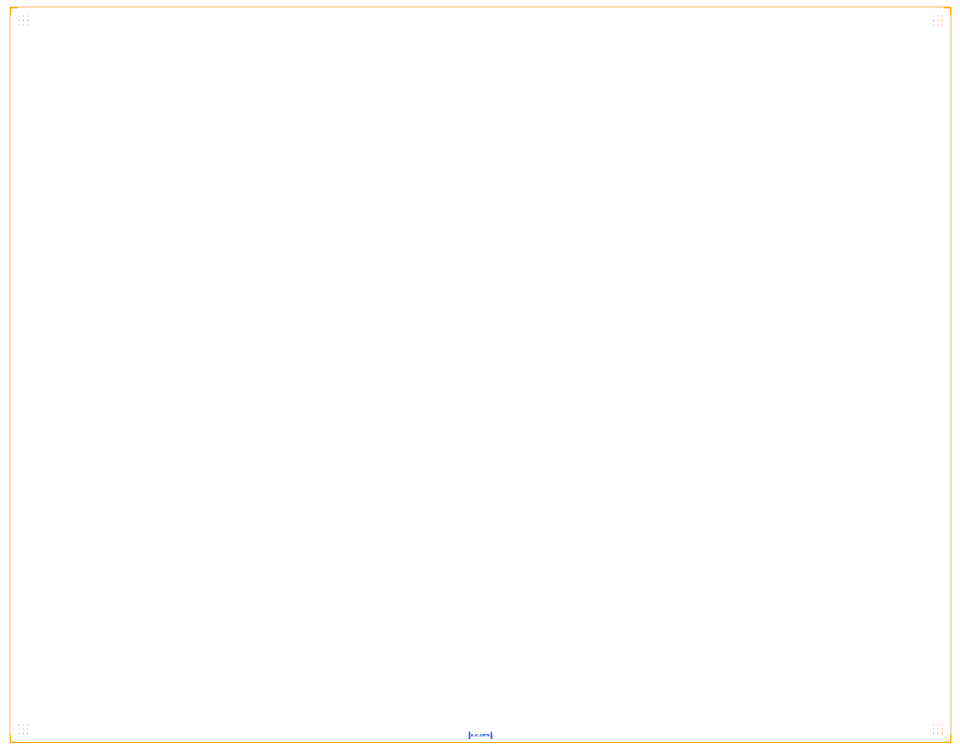

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/iswap1_concentric_direct_s1_die.png')

In [5]:
d = Designer("iswap1_concentric_direct", box=(0, 0, 32000, 25000), chip={"name_chip": "MetalISWAP1"}, live=LIVE)
X0, Y0 = 15000, 7500                             # Metal's chip spans x −15…17 mm; y −7.5…17.5 mm here (see above)
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm


def turn(x, y, deg):                             # rotate a local offset by deg
    c, s = math.cos(math.radians(deg)), math.sin(math.radians(deg))
    return x * c - y * s, x * s + y * c


layout_step(d, OUT / "iswap1_concentric_direct_s1_die.png", size=(960, 750), width=400)

## Design 2 · Bond pads: the PDK pad rule

The tutorial's three `LaunchpadWirebond`s (0.5 × 1 mm pads, no lead) sit 0.8–1.3 mm inside the chip: `P1_C` (the
drive line) and `P2_C` (resonator 2's line) with their pads pointing **south**, `P3_C` (resonator 1's line) pointing
**east**. In the Quantcore PDK the outer edge of every bond pad's etch sits **`frame.pad_edge` = 100 µm from the
die edge**: `edge="s"` / `"e"` slides each pad perpendicular to the edge it faces until it is there, keeping its
position along that edge. Three pieces of drawn geometry end on these pads (P1_C's metal patch inside qubit 1's
pocket, route6, and the ends of the two `PolylineCPW`s): Designs 3 and 7 draw them **from the pads' tie ports**, so they
follow wherever the rule puts the pads.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| P1_C | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| P2_C | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| P3_C | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |

pad ties (µm): {'P1_C': (15000.0, 1280.0), 'P2_C': (2000.0, 1280.0), 'P3_C': (30720.0, 14500.0)}


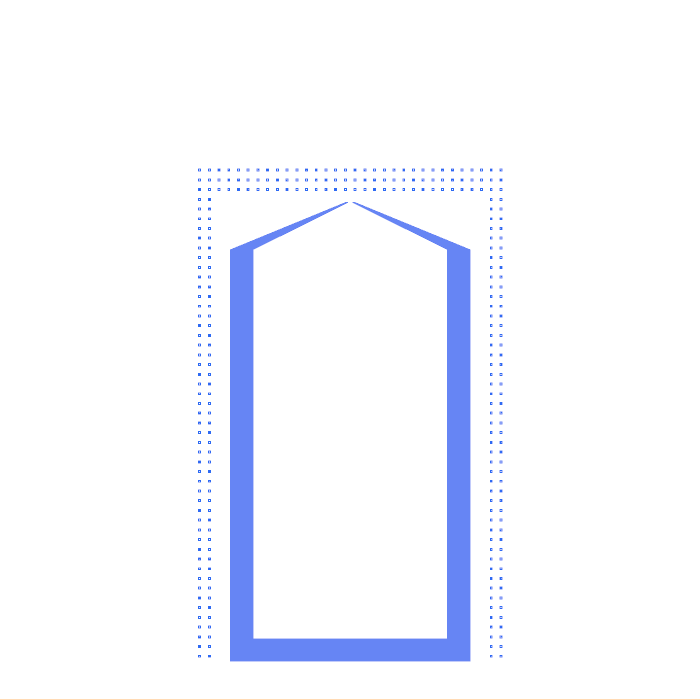

**On the chip so far:** 3 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 3 component(s) `P1_C`, `P2_C`, `P3_C`.

WindowsPath('examples/designs/metal/iswap1_concentric_direct_s2_pads.png')

In [6]:
with d.batch():
    for n, (x, y), r, e in (("P1_C", (0, -5000), 90, "s"), ("P2_C", (-13000, -5000), 90, "s"),
                            ("P3_C", (15000, 7000), 180, "e")):
        d.add(n, "metal:LaunchpadWirebond", at=P(x, y), rot=r, edge=e, pad_width="0.5mm", pad_height="1mm",
              lead_length="0um")
rebuild(d)
display(Markdown(pads_md(d)))
TIE = {n: port_xy(d, f"{n}.tie") for n in ("P1_C", "P2_C", "P3_C")}
print("pad ties (µm):", {n: (round(x, 1), round(y, 1)) for n, (x, y) in TIE.items()})
layout_step(d, OUT / "iswap1_concentric_direct_s2_pads.png", box=(TIE["P2_C"][0] - 900, 0, TIE["P2_C"][0] + 900, 1800),
            size=(700, 700), width=300)

## Design 3 · Readout side: the lumped resonators and their lines to the pads

**The resonators.** `metal:ResonatorLumped` (a 14-turn meander in a 5 × 5 mm metal frame) at ±45°. Each gets a pocket (`metal:Rectangle`, `subtract: true`): the box inside its 10 µm frame (4980 × 4980 µm)
plus a 200 × 720 µm slot through the frame's top break around the `final` segment, so the meander is shorted to the
frame (ground) and ends open at `pin_n`: the λ/4 the LOM model describes.

- **Outside the pockets** (route4 / route5 from the resonators' side pins to `P3_C` / `P2_C`): `metal:PolylineCPW`
  (100 / 6 µm) on Metal's own corner points, wired to the pins at both ends. Their last points are the pad ties of Design 2 (`mm(TIE[...])`), so the 100 µm pad rule only lengthens
their final straight. As the source wires them (by the frame pins `pin_east` / `pin_west`), they end on the frame,
which is ground once the pocket is inside it: the resonators couple to nothing (see the title's consequences).

resonator1 ports: ['pin_east', 'pin_n', 'pin_ne', 'pin_nw', 'pin_s', 'pin_se', 'pin_sw', 'pin_west']


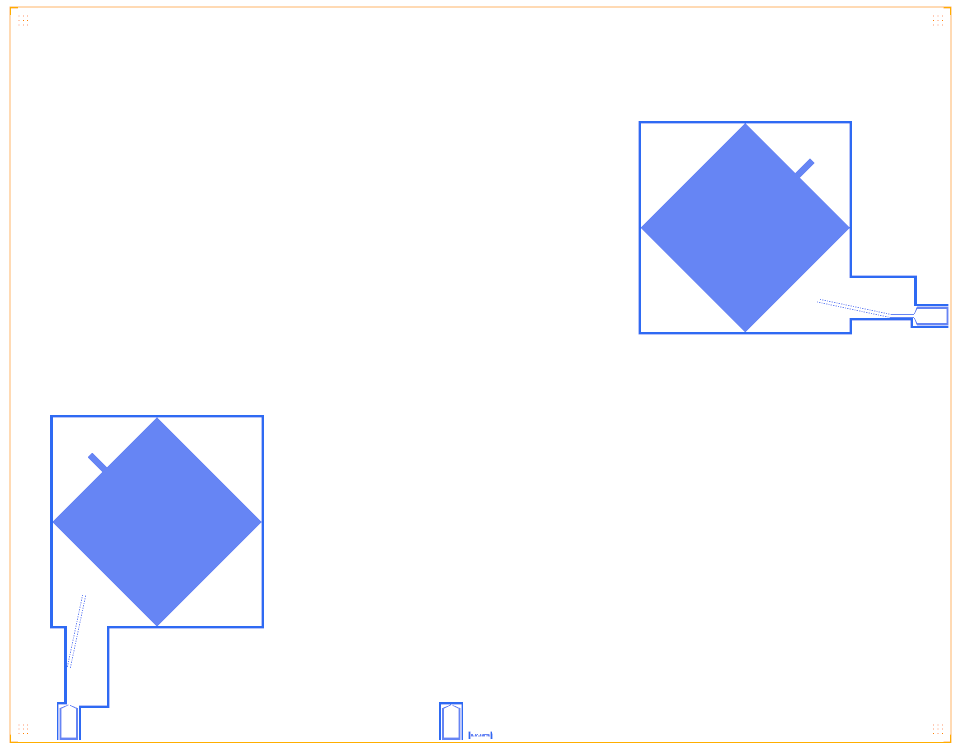

**On the chip so far:** 3 pads · 0 qubits · 8 other components · 0 routes · 4 declared couplings. **This step added** 8 component(s) `resonator1`, `resonator1_pocket`, `resonator1_slot`, `resonator2`, `resonator2_pocket`, `resonator2_slot`, `route4`, `route5`.

WindowsPath('examples/designs/metal/iswap1_concentric_direct_s3_resonators.png')

In [7]:
mm = lambda xy: [round((xy[0] - X0) / 1000, 5), round((xy[1] - Y0) / 1000, 5)]   # Designer µm → Metal mm
with d.batch():
    for n, (x, y), r in (("resonator1", (10000, 10000), -45), ("resonator2", (-10000, 0), 45)):
        d.add(n, "metal:ResonatorLumped", at=P(x, y), rot=r)
        # pocket: inside the 10 µm frame, plus a slot through the 200 µm top break around `final` (pin_n at +3110)
        d.add(f"{n}_pocket", "metal:Rectangle", at=P(x, y), rot=r, width=4980, height=4980, subtract=True)
        dx, dy = turn(0, 2850, r)
        d.add(f"{n}_slot", "metal:Rectangle", at=P(x + dx, y + dy), rot=r, width=200, height=720, subtract=True)
    # lines outside the pockets: Metal's CPW on Metal's own route points (mm, Metal frame), ending at the pad ties
    for n, a, b, pts in (
        ("route4", "resonator1.pin_east", "P3_C.tie", [[11.76777, 8.23223], [12.47487, 7.52513], [14.95, 7.0],
                                                       mm(TIE["P3_C"])]),
        ("route5", "resonator2.pin_west", "P2_C.tie", [[-11.76777, -1.76777], [-12.47487, -2.47487], [-13.0, -4.95],
                                                       mm(TIE["P2_C"])])):
        d.add(n, "metal:PolylineCPW", at=P(0, 0), points=pts, **LINE)
        d.couple(f"w_{n}_start", a, f"{n}.start", wire=True)
        d.couple(f"w_{n}_end", b, f"{n}.end", wire=True)
print("resonator1 ports:", sorted(d["resonator1"].ports))
layout_step(d, OUT / "iswap1_concentric_direct_s3_resonators.png", size=(960, 750), width=400)

## Design 4 · Qubit placement: two concentric transmons and their pockets

**The qubits.** `metal:TransmonConcentricType2` (a disk inside a ring with a SQUID between them, three fingers
`pin1`–`pin3`), at −45° and 135°. The source's qubits are SQUIDs, so each gets a **Quantcore SQUID** sized on the PDK
junction rule. The mm-scale islands have C_Σ ≈ 791 fF (this design's LOM before the rebuild): the PDK nominal SQUID
would put them at ≈ 2.1 GHz, so each is sized for 4.0 GHz, the bottom of the PDK band — L_J ≈ 1.85 nH, R_n ≈ 12 kΩ,
**far below the 40–50 kΩ window** (printed): this geometry and the PDK window are incompatible at 4–8 GHz; it is
flagged, not hidden. `junction=` carries L_J / C_J to the LOM.

**The pockets** (`metal:Rectangle`, `subtract: true`): the 10 × 10 mm pocket Metal computes (`pocket_w × pocket_h`) but
leaves commented out, centred on each qubit and rotated with it. Without it the qubit's metal would be ground plane.
The second picture zooms on qubit 1 in its pocket.

{'Lj_nH': 1.8501, 'Cj_fF': 54.6} R_n 12.4 kΩ, fingers 0.91 × 0.6 µm; R_n 12.4 kΩ is outside the process window 40–50 kΩ (f_q 4 GHz with C_Σ 845.8 fF needs E_J/h 88.3 GHz)
qubit1 ports: ['pin1', 'pin2', 'pin3', 'squid_a', 'squid_b']


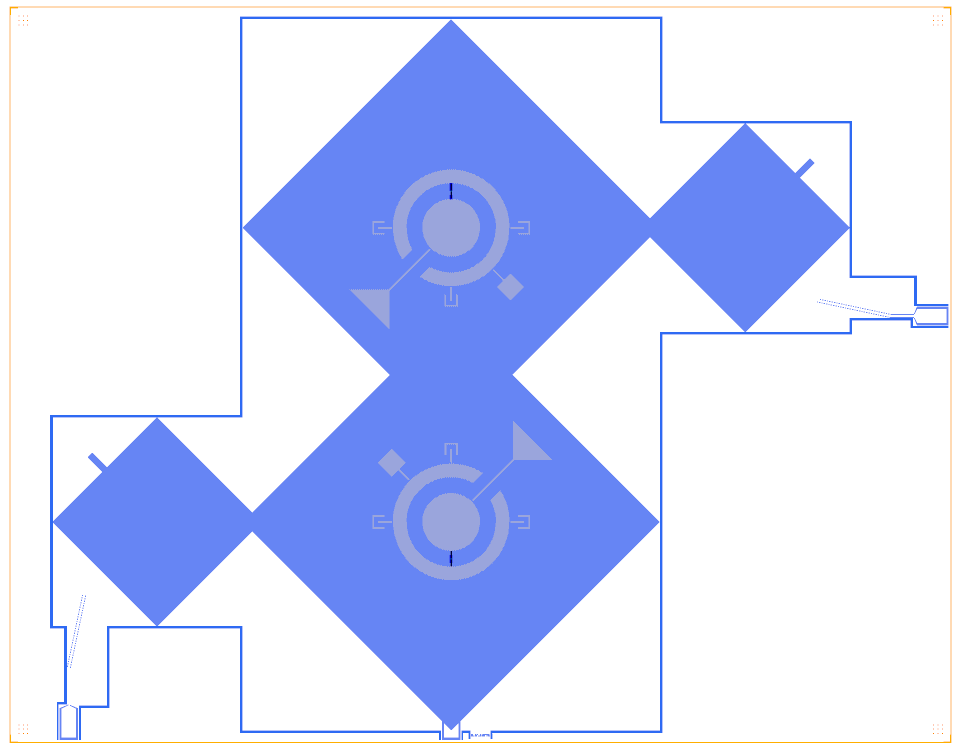

**On the chip so far:** 3 pads · 2 qubits · 10 other components · 0 routes · 4 declared couplings. **This step added** 4 component(s) `qubit1`, `qubit1_pocket`, `qubit2`, `qubit2_pocket`.

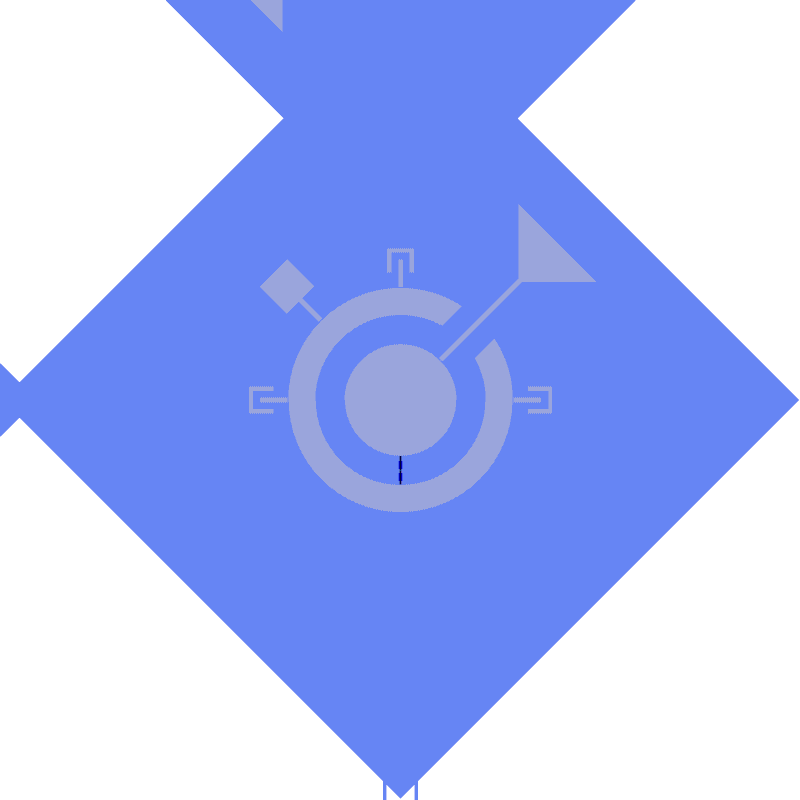

WindowsPath('examples/designs/metal/iswap1_concentric_direct_step_parts.png')

In [8]:
# Quantcore SQUIDs (the source's qubits are SQUIDs) on the PDK rule. The mm-scale islands have C_Σ ≈ 791 fF (this
# design's LOM before the rebuild): the PDK nominal SQUID would put them at ≈ 2.1 GHz, so each is sized for 4.0 GHz,
# the bottom of the PDK band — R_n ≈ 12 kΩ, far below the 40–50 kΩ window (printed)
SIZED = size_junction(4.0, 791.2, n=2, c_includes_junction=False)
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonConcentricType2", lj_nH=SIZED.lj_nH, squid=True)
print(JUNCTION, f"R_n {SIZED.rn_kohm:.1f} kΩ, fingers {SIZED.finger_width} × {SIZED.second_finger_width} µm;", *SIZED.notes)
with d.batch():
    for n, (x, y), r in (("qubit1", (0, 0), -45), ("qubit2", (0, 10000), 135)):
        d.add(n, "metal:TransmonConcentricType2", at=P(x, y), rot=r, junction=JUNCTION, **JJ_PARAMS)
        # the pocket Metal computes (pocket_w × pocket_h, rotated with the qubit) but leaves commented out
        d.add(f"{n}_pocket", "metal:Rectangle", at=P(x, y), rot=r, width=10000, height=10000, subtract=True)
print("qubit1 ports:", sorted(d["qubit1"].ports))
layout_step(d, OUT / "iswap1_concentric_direct_s4_qubits.png", size=(960, 750), width=400)
snap(d, OUT / "iswap1_concentric_direct_step_parts.png", box=P(-7100, -7100) + P(7100, 7100), size=(800, 800), width=360)

## Design 5 · Readout coupling: the lines from the qubits' `pin3` fingers

The lines inside a qubit pocket are drawn the way Metal draws them:
- **Inside a qubit pocket** (route1 between the two `pin2` fingers, route2 / route3 from the `pin3` fingers to the
  resonator frames, route6 from the drive end to `P1_C`): the 100 µm trace as a metal `metal:Rectangle` (Metal draws
  it over the pocket; the gap is inside the pocket anyway), joined to the pins by **wires** (`d.couple(...,
  wire=True)`: a galvanic connection the LOM counts, no drawn route). `P1_C`'s pad now lies at the south tip of qubit
  1's pocket, which would etch the part inside it, so that part is drawn as a 500 µm-wide metal patch (from 100 µm
  below the pocket's tip, clear of the frame's 100 µm die margin, up to the taper).

`strip_line` is that recipe (one metal strip from p0 to p1, one wire between the two pins); here it draws `route2`
(`resonator1.pin_sw` → `qubit2.pin3`) and `route3` (`resonator2.pin_se` → `qubit1.pin3`) on Metal's route points. They
end on the resonator frames, i.e. on ground (Design 3), so the `pin3` fingers are grounded.

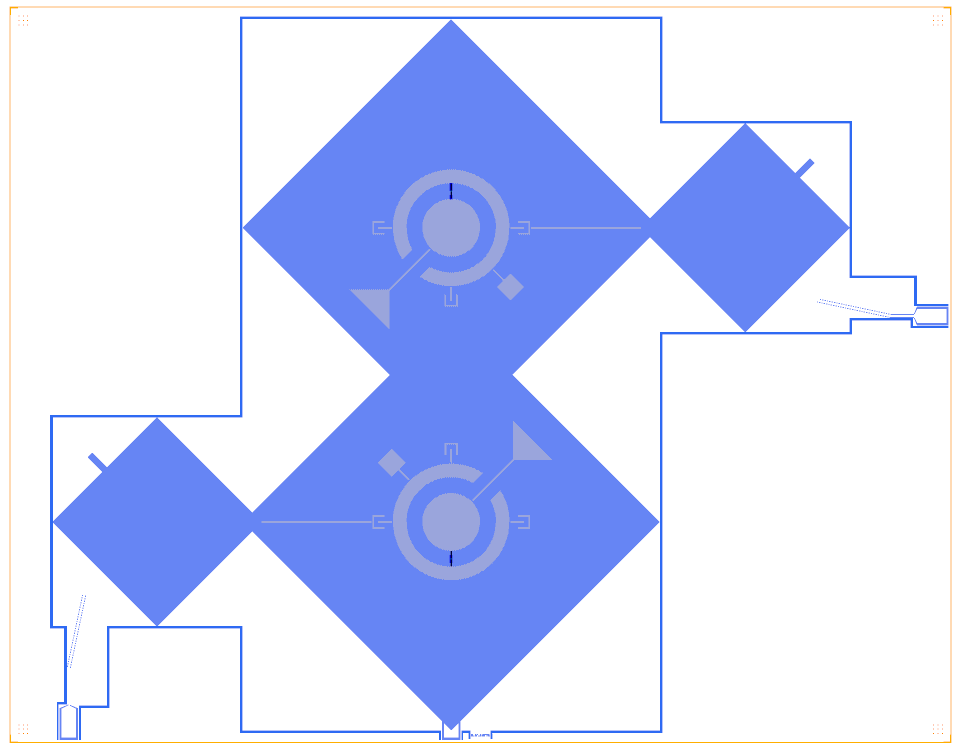

**On the chip so far:** 3 pads · 2 qubits · 12 other components · 0 routes · 6 declared couplings. **This step added** 2 component(s) `route2`, `route3`.

WindowsPath('examples/designs/metal/iswap1_concentric_direct_s5_qubit_lines.png')

In [9]:
def strip_line(n, a, b, p0, p1):
    """A line inside a qubit pocket (Metal draws it over the pocket): its 100 µm trace as a metal rectangle from p0 to
    p1, joined to the pins a and b by a wire (a galvanic connection the LOM counts, no drawn route)."""
    (x0, y0), (x1, y1) = p0, p1
    d.add(n, "metal:Rectangle", at=((x0 + x1) / 2, (y0 + y1) / 2),
          rot=math.degrees(math.atan2(y1 - y0, x1 - x0)), width=math.hypot(x1 - x0, y1 - y0), height=100)
    d.couple(f"w_{n}", a, b, wire=True)


with d.batch():
    # lines inside a qubit pocket: their 100 µm trace, joined to the pins by wires
    strip_line("route2", "resonator1.pin_sw", "qubit2.pin3", P(6464.47, 10000), P(2700, 10000))
    strip_line("route3", "resonator2.pin_se", "qubit1.pin3", P(-6464.47, 0), P(-2700, 0))
layout_step(d, OUT / "iswap1_concentric_direct_s5_qubit_lines.png", size=(960, 750), width=400)

## Design 6 · Coupling: the direct line between the two qubits

The two qubits couple directly through `route1`, a straight 4.6 mm line between their `pin2` fingers (Metal
`RouteStraight`, 100 µm trace), drawn inside the pockets as a metal strip with a wire (`strip_line`). The LOM counts the
wire as one node joining the two fingers (its own capacitance is not in the LOM; the Q3D job `qubits` measures it).

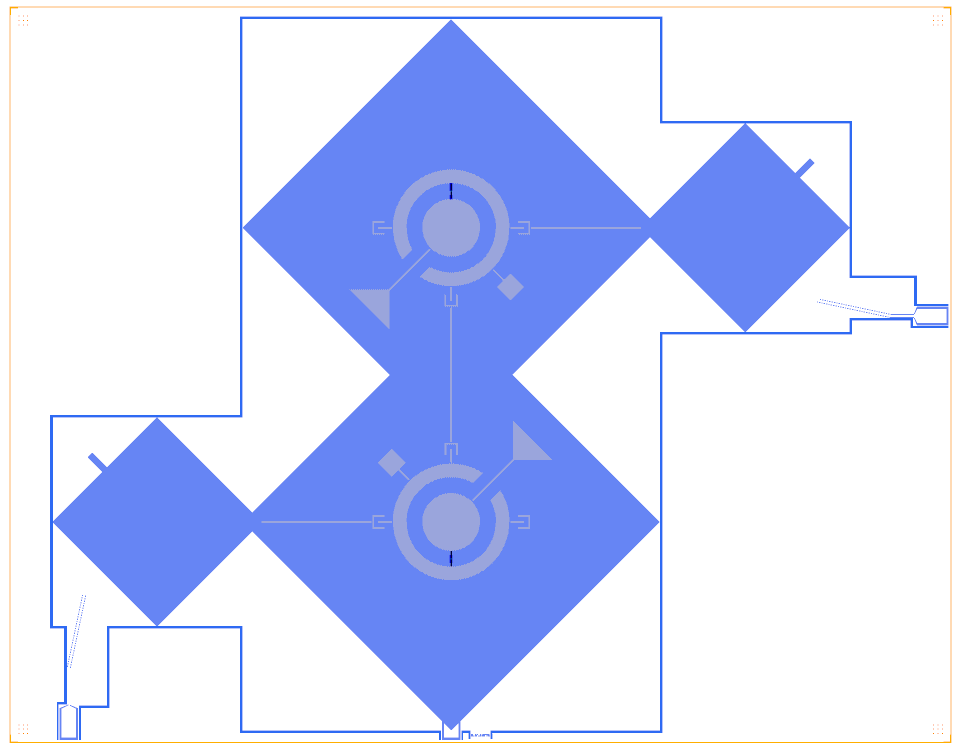

**On the chip so far:** 3 pads · 2 qubits · 13 other components · 0 routes · 7 declared couplings. **This step added** 1 component(s) `route1`.

WindowsPath('examples/designs/metal/iswap1_concentric_direct_s6_coupling.png')

In [10]:
with d.batch():
    strip_line("route1", "qubit1.pin2", "qubit2.pin2", P(0, 2700), P(0, 7300))
layout_step(d, OUT / "iswap1_concentric_direct_s6_coupling.png", size=(960, 750), width=400)

## Design 7 · Routing: the drive line

The drive line ends open: a `metal:OpenToGround` 500 µm below qubit 1's ring (`open1i`), then `route6` from it to
`P1_C` (a metal strip with a wire, inside qubit 1's pocket). `P1_C`'s pad now lies at the south tip of that pocket,
which would etch the part inside it, so that part is drawn as a 500 µm-wide metal patch `P1_C_pad` (from 100 µm below
the pocket's tip, clear of the frame's 100 µm die margin, up to the taper). Both are placed from `P1_C`'s tie
(`t1x, t1y`, Design 2), so the pad rule only lengthens them.
- **Drive coupling:** the drive line's 100 µm open end faces qubit 1's 500 µm ring across 500 µm with no ground near
  (inside the pocket): a coplanar-strip estimate, declared as `Cd_qubit1` (rough).

C_d(drive end ↔ qubit1 ring): 6.0 fF (estimate)


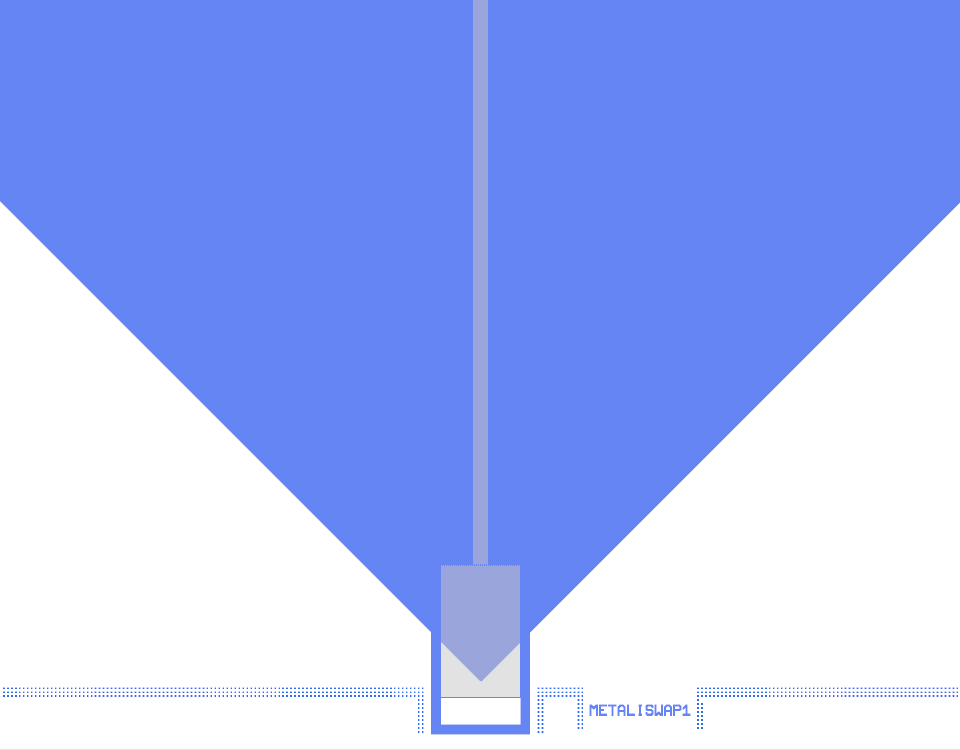

**On the chip so far:** 3 pads · 2 qubits · 16 other components · 0 routes · 9 declared couplings. **This step added** 3 component(s) `open1i`, `route6`, `P1_C_pad`.

WindowsPath('examples/designs/metal/iswap1_concentric_direct_s7_drive.png')

In [11]:
EPS = est.substrate_eps(get_pdk())
C_D = round(est.coplanar_coupling(100, 100, 500, 500, EPS), 2)
print("C_d(drive end ↔ qubit1 ring):", C_D, "fF (estimate)")
t1x, t1y = TIE["P1_C"]                           # P1_C's tie: its pad hangs 122 µm (taper) + 1000 µm below it
with d.batch():
    d.add("open1i", "metal:OpenToGround", at=P(0, -2500), rot=90)
    strip_line("route6", "open1i.open", "P1_C.tie", P(0, -2500), (t1x, t1y - 122))
    # P1_C's pad lies at the tip of qubit1's pocket, which would etch it: the part inside the pocket is drawn as
    # metal (route6 covers its taper); it starts 100 µm below the pocket's tip, clear of the 100 µm die margin
    tip = P(0, 0)[1] - 5000 * math.sqrt(2)       # the 10 mm pocket, rotated 45°: its south corner
    bottom = max(t1y - 1122, tip - 100)
    d.add("P1_C_pad", "metal:Rectangle", at=(t1x, (bottom + t1y - 122) / 2), width=500, height=t1y - 122 - bottom)
    d.couple("Cd_qubit1", "qubit1.island1", "open1i.open", C_fF=C_D, note="drive end 500 µm below the ring (CPS, rough)")
layout_step(d, OUT / "iswap1_concentric_direct_s7_drive.png", box=(t1x - 3000, 0, t1x + 3000, 4700), size=(960, 750),
            width=400)

## Design 8 · The whole chip: the sim group, the centring check, save

**Sim group** `qubits`: both qubits with their pockets and `route1` (Q3D C-matrix).

**Centring.** The PDK wants the chip content centred in the die. This source is off-centre **on purpose**: Metal centres its
32 × 20 mm chip at x = 1 mm so that the east launchpad fits, while the qubits, their 10 mm pockets and the two
resonators are centred on x = 0; the rebuild's box keeps that (Designer = Metal + (15, 7.5) mm). The pad rule then
moved P1_C / P2_C to the south edge and P3_C to the east edge. The cell measures the offsets of everything placed, of
the content without the pads and of the circuit core (qubits, resonators and their pockets), and tries
`center_in_die` on a copy: it counts the pads, which slide back to their edges after a shift, so it would move the
core further west (and break the pad-linked geometry of Designs 3 and 7). The design keeps the source's placement.

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's): the segments above changed how the chip is built, not the chip, so it should say *same design*. The
file keeps the previous key order (the resonators and their lines were added before the qubits here), so `git diff`
stays empty.

content centre − die centre (µm): {'everything': (396, -164), 'without the pads': (-194, -52), 'circuit core': (-1000, 0)}


**Same design as before:** `examples/designs/metal/iswap1_concentric_direct.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

center_in_die on a copy: shift (-395.9, 164.5) µm → circuit core then at (-1396, 164) µm from the die centre
<Designer iswap1_concentric_direct: 21 instances, 0 routes, live=False> → examples\designs\metal\iswap1_concentric_direct.json


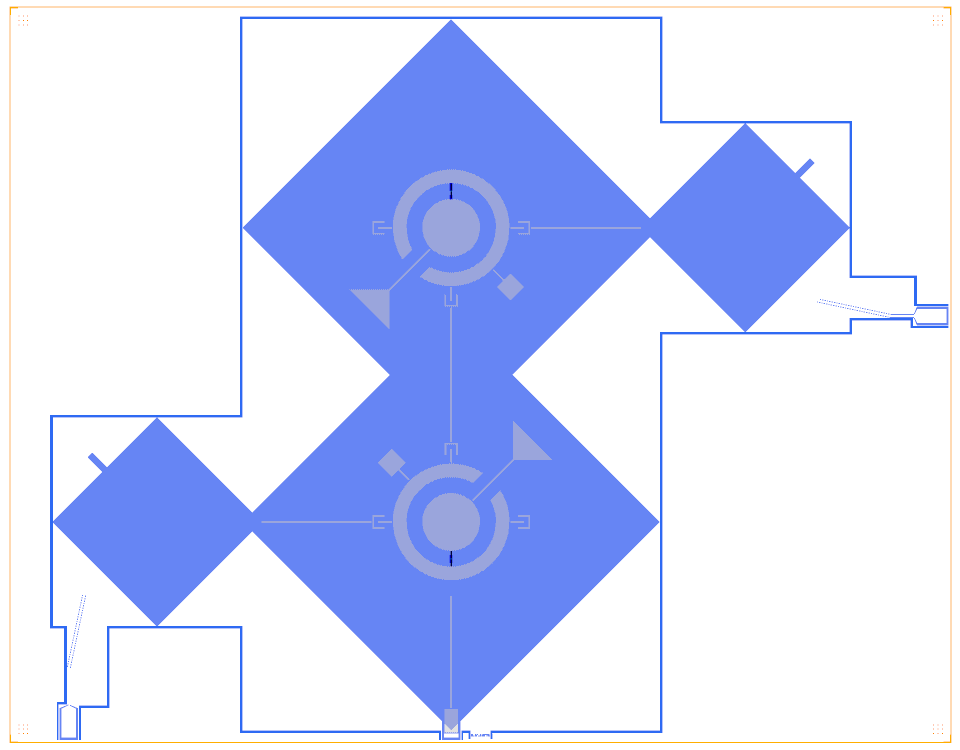

**On the chip so far:** 3 pads · 2 qubits · 16 other components · 0 routes · 9 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/iswap1_concentric_direct_step_routes.png')

In [12]:
# FEM box: both qubits with their pockets and the line between them
d.sim_group("qubits", ["qubit1", "qubit2", "route1", "qubit1_pocket", "qubit2_pocket"], margin_um=200,
            analyses=["q3d_cmatrix"])
from collections import Counter
from kqcircuits.pya_resolver import pya
from quantcore_circuits.assembly.sidecar import sidecar_dict
from _common import _pad_instances


def centre_offsets(d, core=()):
    """Content centre − die centre (µm): of everything placed, without the bond pads, and of the ``core`` instances."""
    side, pads = sidecar_dict(rebuild(d), overlays=False), set(_pad_instances(d))
    x0, y0, x1, y1 = d.design.chip.box
    out = {}
    for label, keep in (("everything", lambda n: True), ("without the pads", lambda n: n not in pads),
                        ("circuit core", lambda n: n in core)):
        box = pya.DBox()
        for n, inst in side["instances"].items():
            if inst.get("bbox") and keep(n):
                box += pya.DBox(*inst["bbox"])
        if label != "circuit core":
            for route in side["routes"].values():
                for x, y in route.get("polyline") or []:
                    box += pya.DPoint(x, y)
        out[label] = (round(box.center().x - (x0 + x1) / 2), round(box.center().y - (y0 + y1) / 2))
    return out


CORE = ["qubit1", "qubit2", "qubit1_pocket", "qubit2_pocket", "resonator1", "resonator2", "resonator1_pocket",
        "resonator2_pocket"]
print("content centre − die centre (µm):", centre_offsets(d, CORE))
DESIGN, same = save_design(d, OUT / "iswap1_concentric_direct.json")
display(Markdown(same))
trial = design_copy(DESIGN, "_centred")          # what center_in_die would do, on a copy
print("center_in_die on a copy: shift", center_in_die(trial), "µm → circuit core then at",
      centre_offsets(trial, CORE)["circuit core"], "µm from the die centre")
print(d, "→", DESIGN)
layout_step(d, OUT / "iswap1_concentric_direct_step_routes.png", size=(960, 750), width=400)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here (from the v1 run): **no errors**. `dangling_port`: the unused pins (each qubit's `pin1`, six of each resonator's
frame pins and its open `pin_n`), the junction attachment points `squid_a` / `squid_b` (drawn by the cell), and the
ends joined by wires (the DRC does not count wire couplings yet, see lom's request). Every `overlap` is a pocket by
design: the two 10 mm qubit pockets overlap each other, the resonators' corners and the lines and patch inside them;
each resonator overlaps its own pocket, slot and lines; P1_C sits at the tip of qubit 1's pocket. **PDK design
warnings:** `pdk_rn` on both qubits: the SQUID is 12.4 kΩ (two ≈ 24.7 kΩ junctions in parallel), far below the
40–50 kΩ window, because mm-scale islands need L_J ≈ 1.85 nH to reach 4 GHz; flagged, not retuned. No `pad_edge`: the three
pads are at 100 µm.

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [ ]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: `TransmonConcentricType2` on its pocket → two floating islands
(`island1` ring, `island2` disk) with the SQUID between, and a coupler node per finger (`pin1`–`pin3`);
`ResonatorLumped` on its pocket → a λ/4 line of its trace length (69.8 mm, shorted to the frame = ground, open at
`pin_n`; rough: no inter-turn coupling). route1 joins the two `pin2` fingers into one node (a wire: its own
capacitance is not in the LOM). The `pin3` fingers are wired to the grounded frames, so their coupling capacitances
go to ground. The drive line is the `P1_C` 50 Ω port node with the assumed `Cd_qubit1` to the ring. P2_C / P3_C are
shorted by the frames (their ports are dropped).

In [ ]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("qubit1.", "P1_C."))})

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

Both qubits with the line between them and the drive port, then each resonator alone. From the v1 run:

- qubit1 / qubit2 at the 4.0 GHz the SQUIDs were sized for (mm-scale islands: C_Σ ≈ 0.8 pF, E_C ≈ 24 MHz). The two
  qubits are identical, so their modes hybridise through route1 (participations ≈ 0.5 each, each mode's
  anharmonicity about half of E_C): ZZ is not defined for degenerate qubits. κ through the drive line is tiny (the
  assumed 6 fF).
- resonator1 / resonator2: λ/4 of the 69.8 mm meander, ≈ 0.45 GHz (rough: no inter-turn coupling, which would lower
  it), κ 0 (nothing couples to it, see the substitutions).

In [ ]:
pair = simulate_groups(d, {"qubit1+route1+qubit2": ["qubit1", "qubit2", "route1", "open1i", "route6", "P1_C"]},
                       max_modes=2)
display(Markdown("**qubit1–route1–qubit2, QuCat normal modes:**\n\n" + modes_md(pair["qubit1+route1+qubit2"])))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(pair)))
res = simulate_groups(d, {"resonator1": ["resonator1"], "resonator2": ["resonator2"]}, max_modes=1)
for g, r in res.items():
    display(Markdown(f"**{g}:**\n\n" + modes_md(r)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each simulated group (QuCat; circles are qubits, squares
resonators; filled markers are the QuTiP dressed values), (b) the dispersive shifts (none: nothing couples to the
resonators). From the v1 run the two qubit modes sit 0.6 MHz apart at 3.97 GHz (a hybridised pair) and both resonators
at 0.45 GHz.

In [ ]:
plot_lom({**pair, **res}, OUT / "iswap1_concentric_direct_lom.png", title="iswap1: LOM per sub-circuit")

## LOM 3 · One geometry change, by hand

Before the FEM, a hand-made design step. Copy the saved design (`design_copy`: a non-live Designer that never writes over the JSON), change one property —
here the SQUIDs' L_J, re-sized for 4.5 GHz instead of 4.0 GHz (smaller L_J, larger fingers, R_n even further below the
window) — and re-run the qubit pair. From the v1 run the pair moves up by ≈ 0.5 GHz; the anharmonicity (set by E_C) barely moves.

In [ ]:
S45 = size_junction(4.5, 791.2, n=2, c_includes_junction=False)
P45, J45 = trilayer_junction("metal:TransmonConcentricType2", lj_nH=S45.lj_nH, squid=True)
print(f"4.5 GHz: L_J {S45.lj_nH:.3f} nH, R_n {S45.rn_kohm:.1f} kΩ")
d2 = design_copy(DESIGN)
for n in ("qubit1", "qubit2"):
    d2[n].set(junction=J45, **P45)               # L_J 1.85 → ≈ 1.46 nH
pair2 = simulate_groups(d2, {"qubit1+route1+qubit2": ["qubit1", "qubit2", "route1", "open1i", "route6", "P1_C"]},
                        max_modes=2)
display(Markdown(params_delta_md(pair, pair2)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/metal/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

Two jobs of the one sim group: a **Q3D C-matrix** for the two qubits, their pockets and route1 (and the same box in
eigenmode, Simulate 3); it replaces the LOM's rough disk /
ring / finger estimates by net name.

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/metal/fem/: solved results are kept here
jobs = export_sims(DESIGN, ["qubits"])
jobs_eig = export_sims(DESIGN, ["qubits"], analysis="eigenmode_epr")   # the same box in eigenmode (no new group)
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrix

The capacitance of the two qubits: each disk, ring and finger and `route1` as named nets (the pockets are the gaps
between them and the ground). It replaces the LOM's rough disk / ring / finger estimates by net name (Results 3).
`fem_stage` solves the job with `RUN_FEM`, else loads its kept results, else says that there are none. The box is
≈ 15 mm across (the 10 mm pockets): the slowest job of this batch.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The `qubits` box in HFSS eigenmode (the same sim group, another analysis; nothing is added to the design): both SQUIDs
are lumped L_J ‖ C_J sheets, so it solves the coupled pair as drawn — the two qubit modes, their splitting (the direct
coupling through `route1`) and their participations. pyEPR (run inside qcc's own AEDT, never KQC's
`run_pyepr_t1_estimate.py`) gives the dressed frequencies and the Kerr terms. At ≈ 4 GHz in a 15 mm box, the box's own
modes may come close: read the p_J of each mode.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run

Not exported for this chip: there is no readout to drive (the resonators couple to nothing once their frames are
ground, Design 3), and the drive line ends open below qubit 1.

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the participation p_J of the first junction, with the LOM's qubit frequencies as dashed lines. The table
below lists every mode with each junction's participation.

In [ ]:
lom_f = {q: pair["qubit1+route1+qubit2"].params.get(f"{q}.f_q_GHz") for q in ("qubit1", "qubit2")}
plot_eigenmodes(keep_eig, OUT / "iswap1_concentric_direct_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms, one qubit at a time: each qubit's mode is the one its own SQUID participates in
most; f_q is pyEPR's dressed frequency, α its self-Kerr. There is no readout (`epr_values` gets a placeholder readout
and only the qubit's own values are kept). With identical qubits the two modes are the split pair (p_J ≈ 0.5 each).

In [ ]:
fem_q = {}
if keep_eig["qubits"]:
    for q in ("qubit1", "qubit2"):
        fem_q.update({k: v for k, v in epr_values(keep_eig["qubits"], {q: "none"}, {"none": 0.0}).items()
                      if k.startswith(f"{q}.")})
if fem_q:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(f"| `{k}` | {v:.5g} |" for k, v in fem_q.items())))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q and α of both qubits from pyEPR.")

## Results 3 · FEM against the LOM

**LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of the qubit pair (LOM 1's group) by the
`qubits` job's C-matrix values (matched by net name) and the same LOM runs again: f_q and α of both qubits. **FEM
directly:** the eigenmode values (Results 2). The left column is the LOM on the component estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill

PAIR = ["qubit1", "qubit2", "route1", "open1i", "route6", "P1_C"]   # LOM 1's group
lom_p = pair["qubit1+route1+qubit2"].params
keys = [f"{q}.{k}" for q in ("qubit1", "qubit2") for k in ("f_q_GHz", "alpha_MHz")]
rows = []
if keep_q3d.get("qubits"):
    on_fem = simulate(fill(d.lom(select=PAIR).model, DESIGN, keep_q3d["qubits"]), max_modes=2).params
    rows += [(key, lom_p.get(key), on_fem.get(key), "LOM on the Q3D C-matrix") for key in keys]
rows += [(key, lom_p.get(key), fem_q[key], "eigenmode + pyEPR") for key in keys if key in fem_q]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q and α of the LOM next to the LOM on the Q3D "
          "C-matrix and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards a target

The tutorial states no targets; its two qubits are identical and hybridise through `route1` (from the v1 run: two
modes 0.6 MHz apart at 3.97 GHz, participations 0.65 / 0.35). This notebook sets one target as an exercise that detunes
them: **qubit2 at 4.20 GHz** (dressed, in the pair's group), which separates the pair. With E_C ≈ 24 MHz (LOM 1) the
transmon formula puts its SQUID at L_J ≈ 1.64 nH (from 1.85 nH).

`loop.feedback` tunes qubit–readout pairs, and this chip has none (the resonators couple to nothing). So the step is a
first-order rule in the notebook: f_q ∝ L_J^−1/2, so **L_J ← L_J · (f_now / f_target)²** (`rule_step`, exponent −0.5).
The new SQUID is drawn (`trilayer_junction(..., lj_nH=..., squid=True)` sizes both fingers and gives C_J) on a copy of
the design (`design_copy`), and qubit2 is measured again in the pair's group (LOM 1).

**No PDK window here.** These mm-scale islands need L_J ≈ 1.6–1.9 nH at 4 GHz, R_n ≈ 11–12 kΩ, far below the
40–50 kΩ window (Design 4, flagged by the DRC): `pdk_lj_bounds` would clamp L_J to ≥ 6 nH, i.e. ≈ 2.1 GHz. So the rule
runs without those bounds. Only L_J moves, so the capacitances do not: when the `qubits` Q3D job is kept (Simulate 2)
its C-matrix fills every revision (the FEM point), otherwise the LOM estimates do.

In [ ]:
from quantcore_circuits.assembly.drc import check

Q_T, F_T, TOL = "qubit2", 4.20, 0.020            # the exercise target: qubit2 at 4.20 GHz ± 20 MHz (dressed, in the pair)
FEM0 = keep_q3d.get("qubits")                     # a kept Q3D job: its C-matrix holds for every revision


def f_q2_of(lj, it):
    """Revision it: qubit2's SQUID drawn for lj nH on a copy, saved; its dressed f_q in the pair (LOM, kept C-matrix)."""
    d_k = design_copy(DESIGN, f"_rev{it}")
    jp, jj = trilayer_junction("metal:TransmonConcentricType2", lj_nH=lj, squid=True)
    d_k[Q_T].set(junction=jj, **jp)
    path = d_k.save(Path("build") / "iswap1_concentric_direct_target" / f"rev{it}.json")
    return simulate(fill(d_k.lom(select=PAIR).model, d_k.design, FEM0), max_modes=2).params.get(f"{Q_T}.f_q_GHz"), path


LJ0 = d.data["instances"][Q_T]["junction"]["Lj_nH"]
F0 = simulate(fill(d.lom(select=PAIR).model, DESIGN, FEM0), max_modes=2).params.get(f"{Q_T}.f_q_GHz")
LJ1 = rule_step(LJ0, F0, F_T, -0.5)
F1, REV1 = f_q2_of(LJ1, 1)
display(Markdown(before_after_md({"qubit2 L_J (nH)": LJ0, "qubit2 f_q (GHz)": F0},
                                 {"qubit2 L_J (nH)": LJ1, "qubit2 f_q (GHz)": F1})))
print(f"target {F_T} ± {TOL} GHz; one step leaves {1e3 * (F1 - F_T):+.1f} MHz · revision 1: {REV1} · DRC:",
      "clean" if check(str(REV1)).ok else "ERRORS")

## Results 5 · Iterate to the target

The rule repeated (`rule_iterate`): revision k gets the new L_J, its LOM runs, and the next step uses the exponent of
the last two points (a secant in log–log), until qubit2 is within 20 MHz or `MAX_ITER` steps are made. Near the start
the pair is hybridised, so the first step's exponent is off; the secant corrects it. The table shows each iteration (on:
FEM when the C-matrix filled it, else LOM), the plot the residual in tolerances (on target below 1).

In [ ]:
history = rule_iterate(f_q2_of, f"{Q_T}.f_q_GHz", f"{Q_T}.junction.Lj_nH", LJ0, F_T, TOL, -0.5, max_iter=MAX_ITER,
                       start=(F0, DESIGN), fem=FEM0 is not None)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "iswap1_concentric_direct_iterate.png")
last = history[-1]["design"]
print("last design:", last, "· DRC:", "clean" if check(str(last)).ok else "ERRORS", "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

The design JSON saved in Design 8 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese.** The iSWAP notebook never exports a GDS, so the original has no cheese: the PDK band applies
(`cheese: "auto"`, the default). The build draws it into KQC's `ground_grid` layer (5 µm squares, 20 µm gaps, three
rows round the 3/0 keep-outs) and `export_fab` keeps it (`cheese source: build`). On this 32 × 25 mm board the fab
export (cheese + corner rounding) is the slowest cell.

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [ ]:
print("design file:", DESIGN)
CHEESE = True
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

## Fab 2 · Snapshots

The full chip (compare the tutorial's screenshot of Example 1); qubit 1 with its fingers, the drive line and route1;
its SQUID between disk and ring; resonator 1's top corner with the slot around `final`; P1_C on the south edge at the
tip of qubit 1's pocket (its metal patch and route6); the **fab mask** at the tip of qubit 1's pocket (1/0 etch with
the PDK cheese band along the pocket edges, the 3/0 keep-out, P1_C); and the die frame's south-west corner.

In [ ]:
show_snapshot(d, OUT / "iswap1_concentric_direct.png", size=(1280, 1000))
show_snapshot(d, OUT / "iswap1_concentric_direct_q1.png", box=P(-3500, -3500) + P(3500, 3500), size=(1000, 1000), width=480)
show_snapshot(d, OUT / "iswap1_concentric_direct_jj.png", box=P(-350, -1600) + P(350, -900), size=(800, 800), width=320)
show_snapshot(d, OUT / "iswap1_concentric_direct_res.png", box=P(10600, 10600) + P(12800, 12800), size=(800, 800), width=320)
show_snapshot(d, OUT / "iswap1_concentric_direct_pad.png", box=(t1x - 1000, 0, t1x + 1000, 2000), size=(800, 800), width=320)
snap_file(Path("build") / "iswap1_concentric_direct_fab.oas", OUT / "iswap1_concentric_direct_cheese.png",
          box=(t1x - 1000, 0, t1x + 1000, 2000), size=(1000, 1000), width=480)
show_snapshot(d, OUT / "iswap1_concentric_direct_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300);

## Summary

| | |
|---|---|
| matches the source | every Metal component and option, positions and orientations, every line on Metal's route points, the sim group |
| PDK changes | QCT frame on a 32 × 25 mm box; sapphire stack; launchpads 100 µm from the south (P1_C, P2_C) and east (P3_C) edges (were 1320 / 1320 / 820 µm in), with their patch, route6 and the polyline ends following the ties; trilayer SQUIDs sized for 4.0 GHz; PDK cheese band |
| differs | the pockets Metal never draws are added; lines inside the pockets are metal strips + wires; the resonators couple to nothing (frame pins are ground once the pockets exist); the source's off-centre placement is kept (Design 8) |
| PDK design warnings | `pdk_rn` × 2 (SQUIDs at 12.4 kΩ: mm-scale islands need L_J ≈ 1.85 nH at 4 GHz) |
| layout | built in segments (die, pads, the resonators with their lines to the pads, the qubits, the qubit–resonator lines, the coupling line, the drive line, the whole chip); the saved JSON is the v1 notebook's |
| feedback | an exercise target (qubit2 4.20 GHz, detuning the hybridised pair) by a first-order SQUID L_J rule on design copies (no qubit–readout pair for `loop.feedback`; no PDK window: R_n ≈ 11 kΩ); LOM, or the Q3D capacitances when the job is kept |
| open | the coupling estimates (wire, drive) until the Q3D job is solved; the FEM jobs (Q3D, eigenmode) are exported, not solved (`RUN_FEM = False`); wires are not counted by the DRC's `dangling_port` |